# 2.4 Entrenamiento disciplinado y modelo final

**Presupuesto declarado:** 20 ensayos de Optuna (TPE, semilla 14) sobre la configuración seleccionada (arquitectura, *L*, estrategia de desbalance), cada uno de hasta 8 épocas con *early stopping* (paciencia 3) y poda por la mediana (`MedianPruner`, 5 ensayos de calentamiento, 2 épocas de gracia). Espacio de búsqueda: tamaño oculto {32, 64, 128}, dropout [0, 0.5], un hiperparámetro estructural (capas / kernel / filtros), lr ∈ [10⁻⁴, 10⁻²] (log), weight decay ∈ [10⁻⁶, 10⁻²] (log) y λ ∈ [0.25, 2] (log). El objetivo es el PR-AUC binario de validación. Después se entrena la **corrida final** con los mejores hiperparámetros (hasta 12 épocas, paciencia 3).

Métricas adicionales de la Entrega 2 sobre la corrida final:

- **F1 macro por componente** (cabeza multiclase).
- **Tiempo de anticipación**: horas entre la primera alerta sostenida (p ≥ umbral durante ≥ 3 h seguidas) y la falla real, con el umbral que maximiza el recall con precisión ≥ 0.80 (`src/metrics.lead_time`).

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plots import set_style, savefig

set_style()
pd.set_option("display.precision", 3)
FIG = ROOT / "entrega2" / "figures"
RES = ROOT / "entrega2" / "results"
RUNS = RES / "runs"


def load_run(name):
    m = json.loads((RUNS / name / "metrics.json").read_text())
    m["history"] = pd.read_csv(RUNS / name / "history.csv")
    return m

from src.data import load_errors, load_failures, load_maint
from src.labels import CLASSES
from src.metrics import confusion

stages = json.loads((RES / "stages.json").read_text())
best = json.loads((RES / "optuna_best.json").read_text())
trials = pd.read_csv(RES / "optuna_trials.csv")
final = load_run("final")
NAMES = {"gru": "GRU", "tcn": "TCN", "cnnlstm": "CNN-LSTM"}
print("configuración:", NAMES[stages["arch"]], "L =", stages["L"], stages["imbalance"])
print("mejor ensayo:", best["best_value"], best["best_params"])


configuración: CNN-LSTM L = 24 weighted
mejor ensayo: 0.9941892284816548 {'hidden': 32, 'dropout': 0.002936892775529165, 'filters': 64, 'lr': 0.0005603888672602156, 'weight_decay': 0.0010225291281781464, 'lam': 1.2221463073852514}


## 1. Búsqueda de hiperparámetros

In [2]:
cols = ["number", "value", "state"] + [c for c in trials.columns if c.startswith("params_")]
summary = trials[cols].rename(columns=lambda c: c.replace("params_", "")).sort_values("value", ascending=False)
summary["estado"] = summary.pop("state").str.lower()
summary.head(8).set_index("number")

,value,dropout,filters,hidden,lam,lr,weight_decay,estado
number,,,,,,,,
1,0.994,0.003,64,32,1.222,5.604e-04,1.023e-03,complete
4,0.993,0.026,32,64,1.779,8.387e-04,8.731e-04,complete
6,0.993,0.269,64,64,0.291,7.213e-04,8.603e-04,complete
0,0.992,0.004,32,128,0.396,4.331e-04,1.435e-04,complete
2,0.991,0.237,64,32,0.488,2.061e-03,5.346e-06,complete
8,0.985,0.037,16,128,0.781,1.117e-03,5.456e-05,pruned
3,0.841,0.031,32,32,0.371,9.611e-03,6.435e-05,complete
18,0.758,0.052,64,32,0.836,4.584e-03,3.354e-04,pruned


completados 6, podados 14


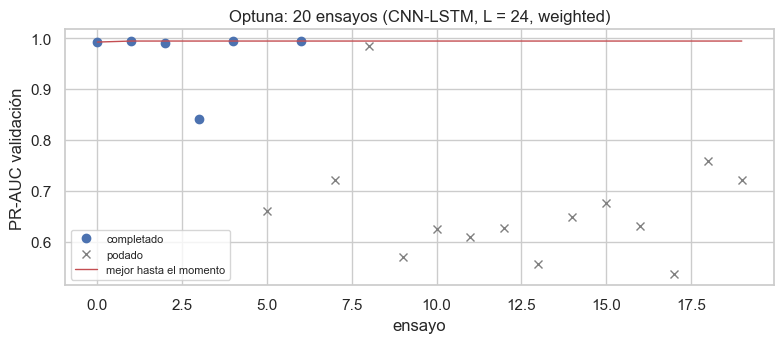

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
done = trials[trials["state"] == "COMPLETE"]
pruned = trials[trials["state"] == "PRUNED"]
ax.plot(done["number"], done["value"], "o", label="completado")
if len(pruned):
    ax.plot(pruned["number"], pruned["value"], "x", color="gray", label="podado")
ax.plot(trials["number"], trials["value"].cummax(), "-", color="#c44e52", lw=1, label="mejor hasta el momento")
ax.set(title=f"Optuna: {len(trials)} ensayos ({NAMES[stages['arch']]}, L = {stages['L']}, {stages['imbalance']})",
       xlabel="ensayo", ylabel="PR-AUC validación")
ax.legend(fontsize=8)
plt.tight_layout()
savefig(fig, "06_optuna", FIG)
print(f"completados {len(done)}, podados {len(pruned)}")

## 2. Corrida final: curvas de aprendizaje

38,742 parámetros · 11 épocas · 13 s/época


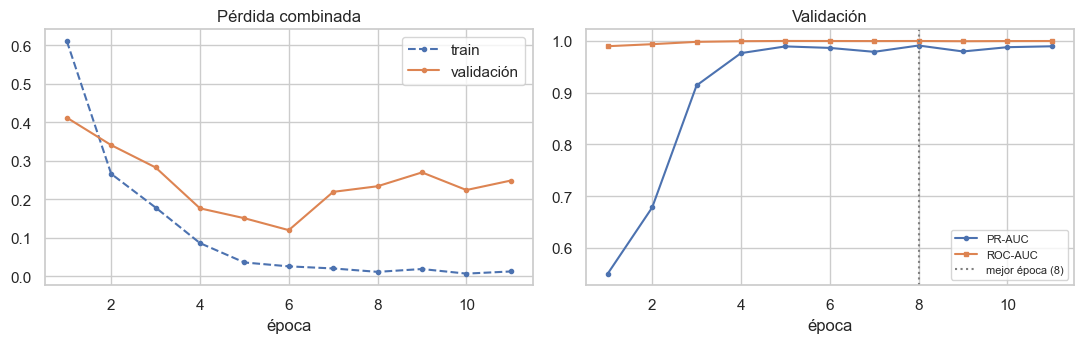

In [4]:
h = final["history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(h["epoch"], h["train_loss"], "--o", ms=3, label="train")
axes[0].plot(h["epoch"], h["val_loss"], "-o", ms=3, label="validación")
axes[0].set(title="Pérdida combinada", xlabel="época"); axes[0].legend()
axes[1].plot(h["epoch"], h["val_pr_auc"], "-o", ms=3, label="PR-AUC")
axes[1].plot(h["epoch"], h["val_roc_auc"], "-s", ms=3, label="ROC-AUC")
axes[1].axvline(final["best_epoch"], color="gray", ls=":", label=f"mejor época ({final['best_epoch']})")
axes[1].set(title="Validación", xlabel="época"); axes[1].legend(fontsize=8)
plt.tight_layout()
savefig(fig, "07_final_learning_curves", FIG)
print(f"{final['n_params']:,} parámetros · {final['epochs']} épocas · {final['seconds'] / final['epochs']:.0f} s/época")

## 3. F1 por componente y matriz de confusión

In [5]:
E1 = ROOT / "entrega1" / "results"
base_conf = pd.read_csv(E1 / "baseline_val_confusion.csv", index_col=[0, 1])


def f1_from_confusion(cm):
    cm = cm.to_numpy()
    tp = np.diag(cm); fp = cm.sum(axis=0) - tp; fn = cm.sum(axis=1) - tp
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)


f1 = {name: dict(zip(CLASSES, f1_from_confusion(base_conf.loc[name]))) for name in base_conf.index.get_level_values(0).unique()}
f1[f"{NAMES[stages['arch']]} final"] = {c: final["f1"][c] for c in CLASSES}
f1 = pd.DataFrame(f1).T
f1["macro"] = f1.mean(axis=1)
f1.to_csv(RES / "f1_per_class.csv")
f1

,ninguno,comp1,comp2,comp3,comp4,macro
Regresión logística,0.999,0.834,0.968,0.927,0.984,0.943
LightGBM,1.000,0.988,1.000,0.999,0.991,0.996
CNN-LSTM final,1.000,0.936,0.952,0.941,0.985,0.963


In [6]:
preds = pd.read_parquet(RUNS / "final" / "val_preds.parquet")
val = pd.read_parquet(ROOT / "data" / "interim" / "val.parquet")[["machineID", "datetime", "y_bin", "y_cls", "h_to_failure"]]
pv = preds.merge(val, on=["machineID", "datetime"])
cm = confusion(pv["y_cls"], pv[[f"p_{c}" for c in CLASSES]].to_numpy(), CLASSES)
cm.to_csv(RES / "final_confusion.csv")
cm

predicho,ninguno,comp1,comp2,comp3,comp4
real,,,,,
ninguno,141244,35,44,5,20
comp1,24,432,0,0,0
comp2,6,0,994,26,0
comp3,1,0,24,449,0
comp4,1,0,0,0,695


## 4. Tiempo de anticipación

In [7]:
lt = pd.read_csv(RUNS / "final" / "lead_time.csv", parse_dates=["datetime"])
summ = lt.groupby("failure", observed=True)["lead_h"].agg(fallas="size", anticipadas=lambda s: s.notna().sum(),
                                                       mediana_h="median", media_h="mean", min_h="min", max_h="max")
summ.loc["total"] = [len(lt), lt["lead_h"].notna().sum(), lt["lead_h"].median(), lt["lead_h"].mean(), lt["lead_h"].min(), lt["lead_h"].max()]
summ["fracción anticipada"] = summ["anticipadas"] / summ["fallas"]
summ.to_csv(RES / "lead_time_summary.csv")
print(f"umbral (precisión ≥ 0.80): {final['umbral']:.3f}")
summ

umbral (precisión ≥ 0.80): 0.014


,fallas,anticipadas,mediana_h,media_h,min_h,max_h,fracción anticipada
failure,,,,,,,
comp1,21.0,20.0,24.0,24.600,24.0,34.0,0.952
comp2,46.0,46.0,24.0,24.000,6.0,33.0,1.000
comp3,20.0,20.0,24.0,27.200,24.0,60.0,1.000
comp4,31.0,31.0,24.0,25.839,6.0,53.0,1.000
total,118.0,117.0,24.0,25.137,6.0,60.0,0.992


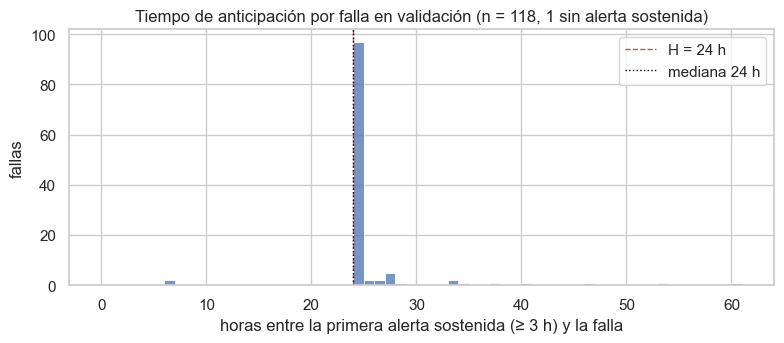

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(lt["lead_h"].dropna(), bins=np.arange(0, lt["lead_h"].max() + 2, 1), ax=ax, color="#4c72b0")
ax.axvline(24, color="#c44e52", ls="--", lw=1, label="H = 24 h")
ax.axvline(lt["lead_h"].median(), color="black", ls=":", lw=1, label=f"mediana {lt['lead_h'].median():.0f} h")
ax.set(title=f"Tiempo de anticipación por falla en validación (n = {len(lt)}, {lt['lead_h'].isna().sum()} sin alerta sostenida)",
       xlabel="horas entre la primera alerta sostenida (≥ 3 h) y la falla", ylabel="fallas")
ax.legend()
plt.tight_layout()
savefig(fig, "08_lead_time", FIG)

## 5. Una máquina vista de cerca

Probabilidad predicha junto con los errores, mantenimientos y fallas reales (recomendación del enunciado).

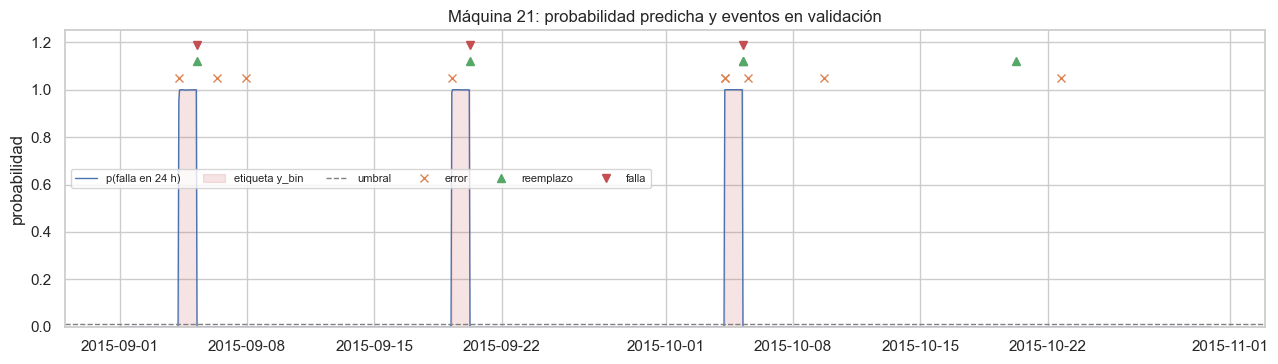

In [9]:
errors, maint, failures = load_errors(), load_maint(), load_failures()
mid = int(lt.groupby("machineID")["lead_h"].size().idxmax())  # la máquina con más fallas en validación
g = pv[pv["machineID"] == mid].sort_values("datetime")
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(g["datetime"], g["p_bin"], color="#4c72b0", lw=1, label="p(falla en 24 h)")
ax.fill_between(g["datetime"], 0, g["y_bin"], color="#c44e52", alpha=0.15, step="mid", label="etiqueta y_bin")
ax.axhline(final["umbral"], color="gray", ls="--", lw=1, label="umbral")
lo, hi = g["datetime"].min(), g["datetime"].max()
for df, col, mk, lab in [(errors, "#dd8452", "x", "error"), (maint, "#55a868", "^", "reemplazo"), (failures, "#c44e52", "v", "falla")]:
    s = df[(df["machineID"] == mid) & (df["datetime"] >= lo) & (df["datetime"] <= hi + pd.Timedelta(hours=24))]
    ax.plot(s["datetime"], np.full(len(s), {"error": 1.05, "reemplazo": 1.12, "falla": 1.19}[lab]), mk, color=col, ms=6, label=lab)
ax.set(title=f"Máquina {mid}: probabilidad predicha y eventos en validación", ylim=(0, 1.25), xlabel="", ylabel="probabilidad")
ax.legend(fontsize=8, ncol=6, loc="center left")
plt.tight_layout()
savefig(fig, "09_machine_timeline", FIG)

## 6. Resumen: ¿supera el deep learning a la línea base?

In [10]:
base_bin = pd.read_csv(E1 / "baseline_val_binary.csv", index_col=0)
rows = []
for name, r in base_bin.iterrows():
    rows.append({"modelo": name, "PR-AUC": r["PR-AUC"], "ROC-AUC": r["ROC-AUC"], "recall@P≥0.80": r["recall@P≥0.80"],
                 "F1 macro": f1.loc[name, "macro"], "anticipación mediana (h)": np.nan, "fallas anticipadas": np.nan})
rows.append({"modelo": f"{NAMES[stages['arch']]} final (L = {stages['L']}, {stages['imbalance']})", "PR-AUC": final["PR-AUC"],
             "ROC-AUC": final["ROC-AUC"], "recall@P≥0.80": final["recall@P≥0.80"], "F1 macro": final["f1"]["macro"],
             "anticipación mediana (h)": final["lead_median_h"], "fallas anticipadas": final["failures_anticipated"]})
fs = pd.DataFrame(rows).set_index("modelo")
fs.to_csv(RES / "final_summary.csv")
fs

,PR-AUC,ROC-AUC,recall@P≥0.80,F1 macro,anticipación mediana (h),fallas anticipadas
modelo,,,,,,
Regresión logística,0.858,0.998,0.836,0.943,NaN,NaN
LightGBM,0.999,1.000,1.000,0.996,NaN,NaN
"CNN-LSTM final (L = 24, weighted)",0.991,1.000,0.992,0.963,24.0,0.992
